# Frekuensi dan Severitas Klaim Kendaraan

Saya meninjau artefak hasil eksekusi pipeline. Notebook ini memverifikasi hash sumber tabel/grafik dan menghitung ulang metrik penting tanpa melatih ulang pada data uji.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image
root = Path.cwd()
manifest = json.loads(Path('reports/artifact_manifest.json').read_text())
for file, expected in manifest.items():
    assert hashlib.sha256(Path(file).read_bytes()).hexdigest() == expected, file
result = json.loads(Path('reports/hasil.json').read_text())
display(result)


{'seed': 2024,
 'sampling_rule': 'simple random sample of policy IDs before 80:20 split',
 'requested_max_policies': 100000,
 'sample_policies': 100000,
 'train_policies': 80000,
 'test_policies': 20000,
 'train_claim_rows': 3091,
 'test_claim_rows': 800,
 'overlap_policy_ids': 0,
 'audit': {'raw_policies': 678013,
  'raw_claim_rows': 26639,
  'duplicate_policy_ids': 0,
  'exact_duplicate_claim_rows': 255,
  'invalid_exposure_rows': 0,
  'exposure_above_one_rows': 1224,
  'nonpositive_claim_rows': 0,
  'missing_cells_freq': 0,
  'missing_cells_sev': 0,
  'severity_ids_absent_from_frequency': 195,
  'severity_unique_ids_absent': 6,
  'count_mismatch_policies': 9117,
  'frequency_claim_total': 36102,
  'matched_positive_claim_total': 26444,
  'positive_claim_frequency_zero_policies': 0},
 'train_cap_q99': 18056.01699999989,
 'train_pearson_dispersion': 2.8672040593351737,
 'nb2_alpha_train_moments': 0.8462319926020041,
 'poisson_train_aic': 33739.49143565665,
 'nb_train_aic_fixed_alpha':

## Frekuensi dengan exposure

Saya menghitung total klaim dibagi total exposure dari data latih, bukan rerata rate tanpa bobot.

In [2]:
table = pd.read_csv('reports/eda_rates.csv')
display(table)

,category,policies,claims,exposure,annual_frequency,factor
0,A,12376,634,7384.839254,0.085852,Area
1,B,8874,398,5075.410615,0.078417,Area
2,C,22611,1152,12231.300753,0.094185,Area
3,D,17826,1015,9029.636701,0.112408,Area
4,E,16102,925,7506.478861,0.123227,Area
5,F,2211,126,994.125009,0.126745,Area
6,Diesel,39177,1980,20040.016595,0.098802,VehGas
7,Regular,40823,2270,22181.774598,0.102336,VehGas
8,R11,8350,495,3589.148323,0.137916,Region
9,R21,357,21,135.961873,0.154455,Region


## Validasi count dan rate

Saya membandingkan model pada polis, respons count, dan exposure uji yang sama.

In [3]:
table = pd.read_csv('reports/evaluation.csv')
display(table)

,model,test_count_poisson_deviance,test_nb2_deviance_at_train_alpha,test_exposure_weighted_rate_deviance,actual_claims,predicted_claims,count_calibration_ratio
0,Poisson GLM,0.334928,0.296648,0.633153,1114,1073.579180,0.963716
1,NB2 GLM,0.334934,0.296630,0.633165,1114,1085.405382,0.974332
2,Gradient boosting,0.319576,0.281785,0.604132,1114,1077.309514,0.967064


## Validasi severitas

Saya membedakan target terbatas dan tanpa batas. AIC lintas target tidak dibandingkan.

In [4]:
table = pd.read_csv('reports/severity_evaluation.csv')
display(table)

,target,test_claim_rows,gamma_deviance,actual_mean,predicted_mean,train_aic
0,limited,800,1.053770,1533.488415,1630.052632,52987.681229
1,unlimited,800,1.397102,1654.378775,2342.037474,62790.046894


## Relativitas dan interval

Saya membaca faktor terhadap kategori referensi dan numerik per satu simpangan baku latih.

In [5]:
table = pd.read_csv('reports/relativities.csv')
display(table)

,model,term,coefficient,relativity,ci_low,ci_high
0,poisson,intercept,-2.101471,0.122276,0.095761,0.156134
1,poisson,category__Area_B,-0.215399,0.806220,0.695996,0.933899
2,poisson,category__Area_C,-0.162544,0.849979,0.705116,1.024602
3,poisson,category__Area_D,-0.189803,0.827122,0.622139,1.099644
4,poisson,category__Area_E,-0.303260,0.738407,0.504321,1.081146
...,...,...,...,...,...,...
167,gamma_unlimited,numeric__VehPower,0.030800,1.031280,0.860146,1.236462
168,gamma_unlimited,numeric__VehAge,0.077245,1.080307,0.877911,1.329363
169,gamma_unlimited,numeric__DrivAge,-0.006550,0.993472,0.828506,1.191285
170,gamma_unlimited,numeric__BonusMalus,0.231781,1.260844,1.092098,1.455664


## Lift berbobot exposure

Saya mengurutkan premi GLM dan membentuk desil dari akumulasi exposure.

In [6]:
table = pd.read_csv('reports/lift.csv')
display(table)

,decile,policies,exposure,actual_annual_cost,actual_lift,period_cost,boost_period_cost
0,1,1669,1058.203813,28.339758,0.244398,64.751484,68.179657
1,2,1646,1057.601106,67.975874,0.586214,85.933114,88.516801
2,3,1685,1058.266545,93.934281,0.810076,100.758061,104.239764
3,4,1728,1057.684864,105.608278,0.910751,114.058239,116.336107
4,5,1729,1058.431228,107.033716,0.923044,128.034069,128.048083
5,6,1855,1057.671180,119.789580,1.033048,143.505922,137.416594
6,7,2098,1058.331265,105.746578,0.911943,162.859370,162.575112
7,8,2319,1057.244256,110.884074,0.956248,187.933908,196.865465
8,9,2554,1058.613504,135.757894,1.170757,230.669843,243.324908
9,10,2717,1057.620839,284.558438,2.453991,426.574551,400.480680


## Double lift

Saya mengurutkan rasio biaya boosting/GLM untuk melihat area ketidaksepakatan model.

In [7]:
table = pd.read_csv('reports/double_lift.csv')
display(table)

,decile,policies,exposure,actual_annual_cost,actual_lift,period_cost,boost_period_cost
0,1,2336,1058.224286,82.929830,0.715175,250.283839,131.530335
1,2,2059,1057.957673,48.185652,0.415546,180.971579,121.360458
2,3,1960,1058.192254,128.246242,1.105977,170.935079,128.402561
3,4,1922,1057.084949,112.736698,0.972225,157.873876,129.369941
4,5,1826,1058.286608,124.371910,1.072566,154.938612,137.442009
5,6,1819,1058.122065,91.766190,0.791379,146.008730,138.872076
6,7,1801,1058.264027,84.089630,0.725177,136.851039,138.992024
7,8,1853,1057.142147,108.896150,0.939105,135.370142,148.859100
8,9,1943,1058.698403,177.496899,1.530708,134.939004,165.869415
9,10,2481,1057.696189,200.840436,1.732019,176.821522,405.279132


## Sensitivitas tail

Saya memakai batas kuantil yang hanya dipelajari dari klaim latih; q95 bukan model refit.

In [8]:
table = pd.read_csv('reports/tail_sensitivity.csv')
display(table)

,train_quantile,train_limit,train_claims_above,test_claims_above,test_total_limited_cost
0,0.95,4820.325,155,38,1055031.810
1,0.99,18056.017,31,6,1226790.732
2,1.0,1403057.400,0,0,1323503.020
3,unlimited,NaN,0,0,1323503.020


## Pemeriksaan konsistensi

Saya menghitung ulang hubungan pokok dari prediksi tersimpan.

In [9]:
from sklearn.metrics import mean_poisson_deviance
pred = pd.read_csv('reports/test_predictions.csv')
assert np.allclose(pred.predicted_count, pred.annual_frequency*pred.Exposure)
assert np.allclose(pred.period_cost, pred.annual_pure_premium*pred.Exposure)
assert np.isclose(pred.limited_amount.sum(), result['test_actual_limited_cost'])
assert np.isclose(mean_poisson_deviance(pred.ClaimNb, pred.predicted_count), result['frequency_evaluation'][0]['test_count_poisson_deviance'])
split = pd.read_csv('reports/split.csv')
assert not set(split.query("split == 'train'").IDpol) & set(split.query("split == 'test'").IDpol)
print('Count, rate, exposure, biaya, deviance, dan pemisahan ID konsisten.')

Count, rate, exposure, biaya, deviance, dan pemisahan ID konsisten.


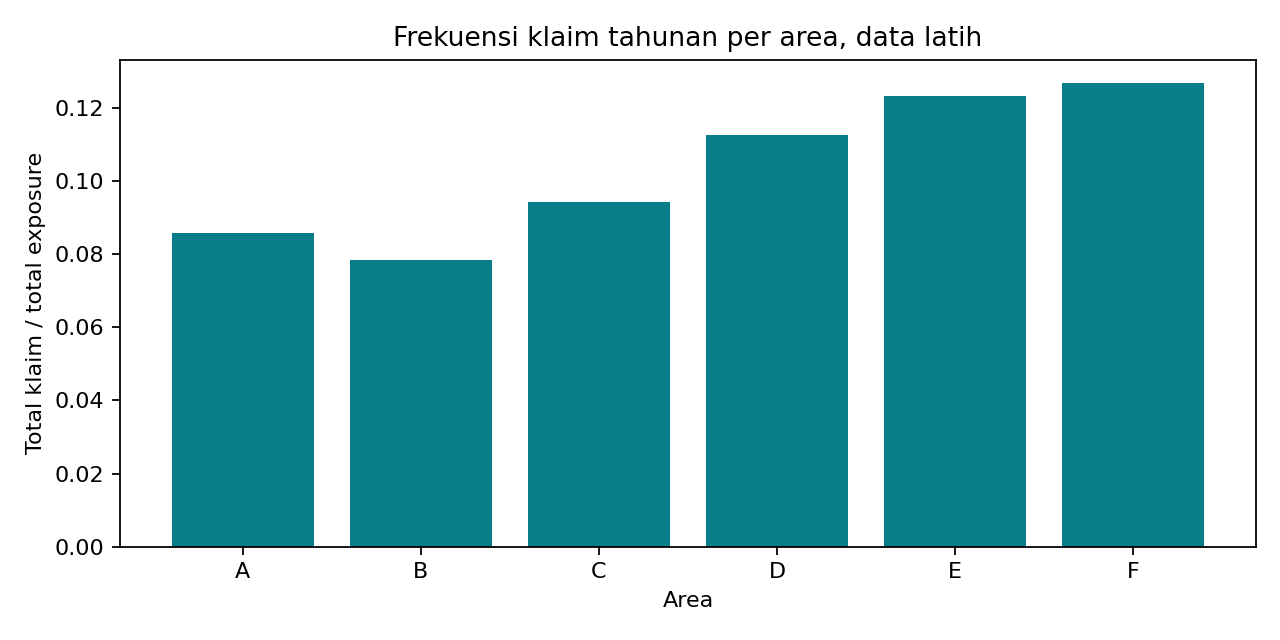

In [10]:
display(Image(filename='assets/frequency_area.png'))

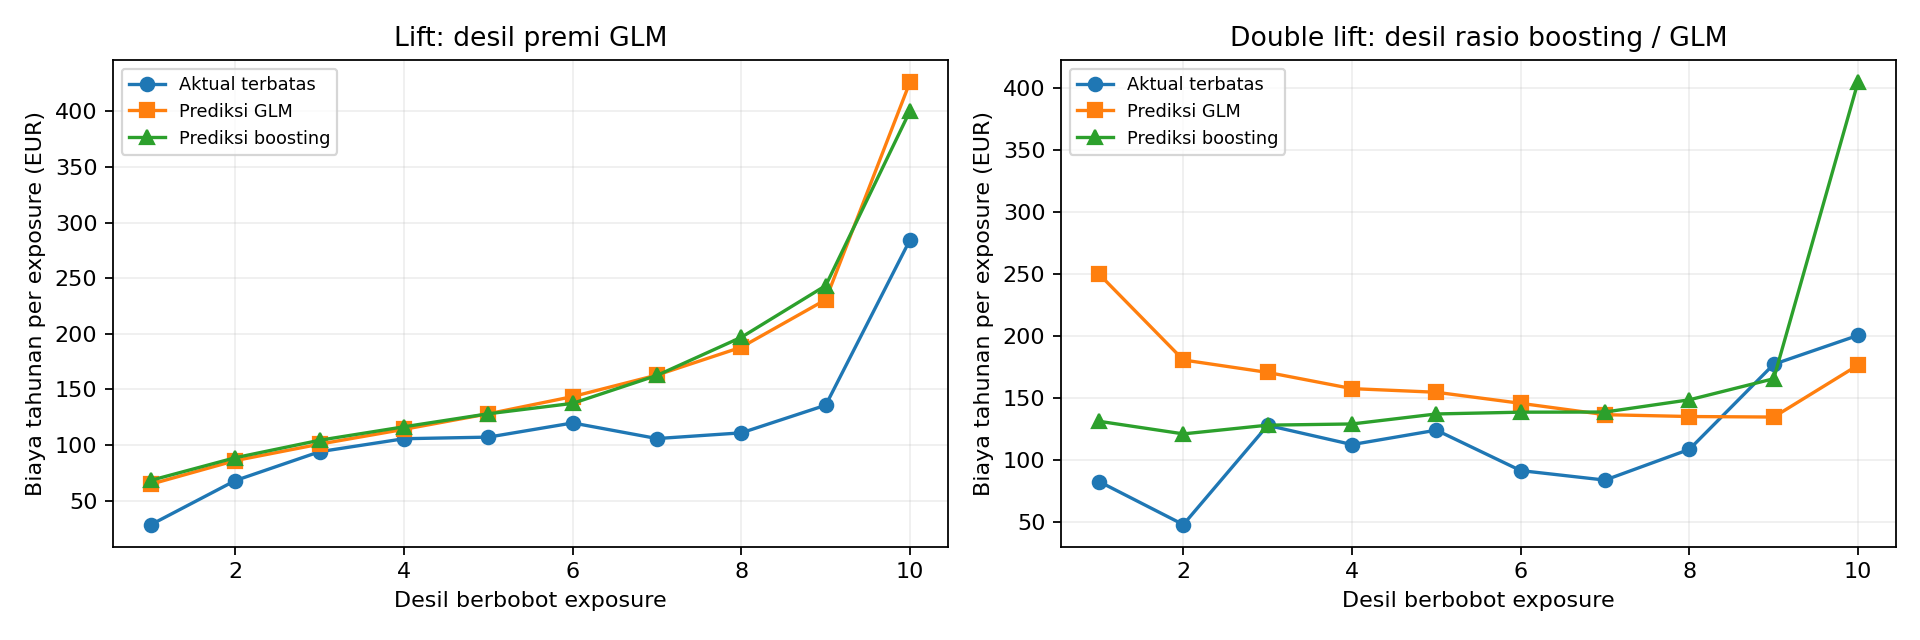

In [11]:
display(Image(filename='assets/lift.png'))

## Interpretasi dan batas penggunaan

Saya membaca hasil sebagai studi portofolio. Penjelasan lengkap, audit data, keputusan berbasis latih, dan keterbatasan tersedia di reports/laporan_analisis.md.